# OOF inspect: alarm vs no-alarm

Join the `hgb_baseline` OOF scores to train. Split on the Cut 1 alarm union. For each region, ranking quality is **within-region ROC AUC**. Calibration is **observed fraud rate vs mean predicted probability**.

The competition metric is ranking. A region is a candidate to improve if occupancy is large, fraud mass is non-trivial, and either:

- within-region AUC is weak, or
- mean `y_prob` does not match the observed rate.

Findings have to hold **per fold**, not only on pooled OOF.

In [1]:
%load_ext autoreload
%autoreload 2

import importlib
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
from ccf_ml.visualization.bivariate import categorical_numeric
importlib.reload(file_utils)
importlib.reload(alarm_mod)
importlib.reload(categorical_numeric)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_oof_path,
)
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "oof_alarm_region_auc"
EXP_NAME = "hgb_baseline"
PROB_COL = "y_prob"
FOLD_COL = "fold_id"
ALARM_SPLIT_COL = "alarm_flag_split"
ALARM_SPLIT_LABELS = {
    False: "no alarm",
    True: "at least one alarm",
}
ALARM_SPLIT_ORDER = ["no alarm", "at least one alarm"]
TARGET_GIVEN_LABELS = {0: "not fraud", 1: "fraud"}
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
train_features = train_df.drop(columns=[TARGET_COLUMN])
frame = train_features.merge(oof_df, on=ID_COLUMN, how="inner", validate="one_to_one")
if len(frame) != len(train_df) or len(frame) != len(oof_df):
    raise ValueError(
        f"join lost rows: train={len(train_df)} oof={len(oof_df)} joined={len(frame)}"
    )
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
frame[ALARM_SPLIT_COL] = has_alarm.map(ALARM_SPLIT_LABELS)
print("exp_name", EXP_NAME)
print("n_rows", len(frame))
print("alarm flags", list(ALARM_FLAG_COLUMNS))
print(frame[[ID_COLUMN, TARGET_COLUMN, PROB_COL, FOLD_COL, ALARM_SPLIT_COL]].head())


exp_name hgb_baseline
n_rows 699960
alarm flags ['ip_country_mismatch', 'is_ai_generated_scam_attempt', 'billing_shipping_mismatch', 'is_foreign_transaction', 'used_vpn']
   id  is_fraud    y_prob  fold_id    alarm_flag_split
0   0         0  0.000298        3            no alarm
1   1         0  0.001530        3            no alarm
2   2         0  0.003552        4  at least one alarm
3   3         0  0.001820        2            no alarm
4   4         0  0.009855        0            no alarm


## Pooled OOF: occupancy, calibration, within-slice AUC

`rate` is the observed fraud frequency. `mean_y_prob` is the model's average score in the region. `auc` is ROC AUC using only rows in that region.

In [2]:
def region_metrics(
    part: pd.DataFrame,
    *,
    universe: pd.DataFrame,
) -> dict[str, object]:
    y = part[TARGET_COLUMN].to_numpy()
    y_int = y.astype(np.int64)
    if not np.all(y == y_int):
        raise ValueError("is_fraud is not integer-valued")
    prob = part[PROB_COL].to_numpy(dtype="float64")
    n = len(part)
    n_universe = len(universe)
    n_fraud = int(np.sum(y_int == 1))
    n_fraud_universe = float(universe[TARGET_COLUMN].sum())
    if n == 0:
        raise ValueError("region is empty")
    if n_universe == 0:
        raise ValueError("universe is empty")
    if n_fraud_universe == 0:
        raise ValueError("universe has no fraud rows")
    rate = n_fraud / n
    mean_y_prob = float(np.mean(prob))
    return {
        "n": n,
        "n_fraud": n_fraud,
        "share_of_rows": n / n_universe,
        "share_of_fraud": n_fraud / n_fraud_universe,
        "rate": rate,
        "mean_y_prob": mean_y_prob,
        "calibration_gap": rate - mean_y_prob,
        "auc": float(roc_auc_score(y_int, prob)),
    }


overall = region_metrics(frame, universe=frame)
print("pooled OOF (all rows)")
print(
    pd.DataFrame([overall], index=["all"])[
        ["n", "n_fraud", "rate", "mean_y_prob", "calibration_gap", "auc"]
    ].round(4)
)
print(DELIMITER_VALUE)

n_regions = len(ALARM_SPLIT_ORDER)
region_rows: list[dict[str, object] | None] = [None] * n_regions
for i in range(n_regions):
    name = ALARM_SPLIT_ORDER[i]
    part = frame.loc[frame[ALARM_SPLIT_COL] == name]
    metrics = region_metrics(part, universe=frame)
    metrics[ALARM_SPLIT_COL] = name
    region_rows[i] = metrics
pooled = pd.DataFrame([row for row in region_rows if row is not None])
pooled = pooled.set_index(ALARM_SPLIT_COL).reindex(ALARM_SPLIT_ORDER)
print(pooled.round(4))
pooled_path = tables_dir / "pooled_alarm_region_metrics.csv"
pooled.to_csv(pooled_path)
print("saved", pooled_path)


pooled OOF (all rows)
          n  n_fraud    rate  mean_y_prob  calibration_gap     auc
all  699960    11689  0.0167       0.0169          -0.0002  0.9416
--------------------------------------------------
                         n  n_fraud  share_of_rows  share_of_fraud    rate  \
alarm_flag_split                                                             
no alarm            646938     6931         0.9242           0.593  0.0107   
at least one alarm   53022     4758         0.0758           0.407  0.0897   

                    mean_y_prob  calibration_gap     auc  
alarm_flag_split                                          
no alarm                 0.0112          -0.0005  0.9267  
at least one alarm       0.0870           0.0028  0.9261  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\oof_alarm_region_auc\tables\pooled_alarm_region_metrics.csv


## Per fold

Same table inside each val fold. A region is only interesting if the AUC / calibration gap repeats across folds.

In [3]:
fold_ids = np.sort(frame[FOLD_COL].unique())
n_folds = len(fold_ids)
n_fold_rows = n_folds * n_regions
fold_rows: list[dict[str, object] | None] = [None] * n_fold_rows
row_i = 0
for fold_i in range(n_folds):
    fold_id = int(fold_ids[fold_i])
    fold_frame = frame.loc[frame[FOLD_COL] == fold_id]
    for region_i in range(n_regions):
        name = ALARM_SPLIT_ORDER[region_i]
        part = fold_frame.loc[fold_frame[ALARM_SPLIT_COL] == name]
        metrics = region_metrics(part, universe=fold_frame)
        metrics[FOLD_COL] = fold_id
        metrics[ALARM_SPLIT_COL] = name
        fold_rows[row_i] = metrics
        row_i += 1
by_fold = pd.DataFrame([row for row in fold_rows if row is not None])
print(
    by_fold.pivot(
        index=FOLD_COL,
        columns=ALARM_SPLIT_COL,
        values="auc",
    ).reindex(columns=ALARM_SPLIT_ORDER).round(4)
)
print(DELIMITER_VALUE)
print(
    by_fold.pivot(
        index=FOLD_COL,
        columns=ALARM_SPLIT_COL,
        values="calibration_gap",
    ).reindex(columns=ALARM_SPLIT_ORDER).round(4)
)
fold_path = tables_dir / "fold_alarm_region_metrics.csv"
by_fold.to_csv(fold_path, index=False)
print("saved", fold_path)


alarm_flag_split  no alarm  at least one alarm
fold_id                                       
0                   0.9305              0.9236
1                   0.9291              0.9200
2                   0.9250              0.9360
3                   0.9225              0.9220
4                   0.9270              0.9303
--------------------------------------------------
alarm_flag_split  no alarm  at least one alarm
fold_id                                       
0                  -0.0002              0.0003
1                  -0.0006              0.0033
2                  -0.0000              0.0018
3                  -0.0008              0.0057
4                  -0.0006              0.0029
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\oof_alarm_region_auc\tables\fold_alarm_region_metrics.csv


## Score CDF given fraud, inside each region

`P(y_prob <= t | is_fraud)` inside no-alarm and inside alarm. If the two class curves sit on top of each other, the model is not ranking inside that region.

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\oof_alarm_region_auc\plots\score_cdf_given_fraud\no_alarm_y_prob_cdf_given_fraud.png


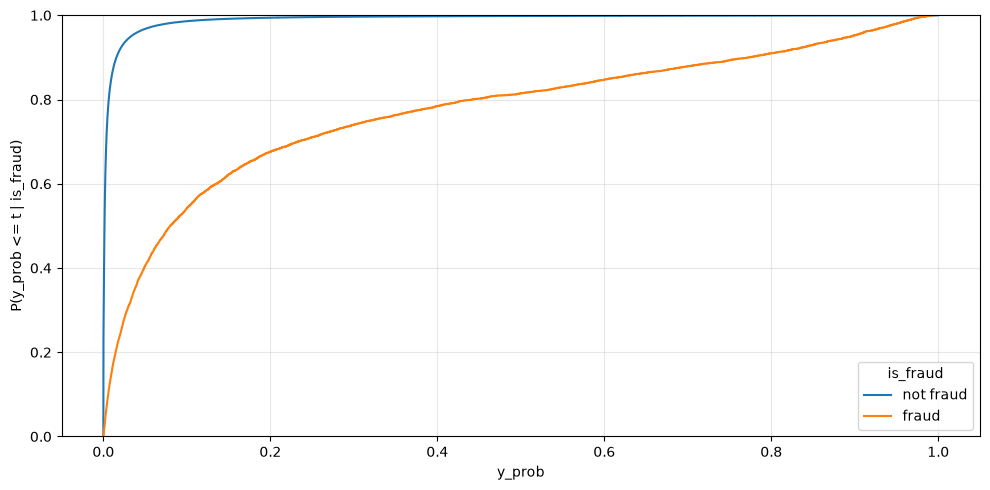

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\oof_alarm_region_auc\plots\score_cdf_given_fraud\at_least_one_alarm_y_prob_cdf_given_fraud.png


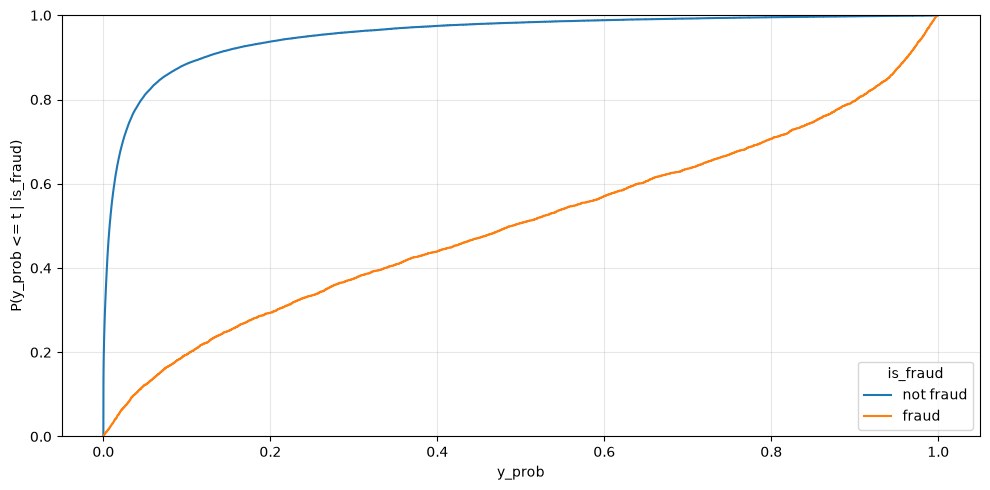

In [4]:
SCORE_SECTION = "score_cdf_given_fraud"

def score_ecdf(part: pd.DataFrame) -> pd.DataFrame:
    levels = [0, 1]
    n_levels = len(levels)
    parts: list[pd.DataFrame | None] = [None] * n_levels
    for i in range(n_levels):
        level = levels[i]
        scores = np.sort(
            part.loc[part[TARGET_COLUMN] == level, PROB_COL].to_numpy(dtype="float64")
        )
        n_scores = len(scores)
        if n_scores == 0:
            raise ValueError(f"no rows for is_fraud={level}")
        cdf = np.arange(1, n_scores + 1) / n_scores
        parts[i] = pd.DataFrame(
            {PROB_COL: scores, "cdf": cdf, TARGET_COLUMN: level}
        )
    filled = [part_i for part_i in parts if part_i is not None]
    return pd.concat(filled, ignore_index=True)


for i in range(n_regions):
    name = ALARM_SPLIT_ORDER[i]
    part = frame.loc[frame[ALARM_SPLIT_COL] == name]
    curves = score_ecdf(part)
    fig, ax = categorical_numeric.plot_conditional_cdf(
        curves,
        x=PROB_COL,
        cdf="cdf",
        group=TARGET_COLUMN,
        x_scale="linear",
        group_labels=TARGET_GIVEN_LABELS,
    )
    ax.set_xlabel(PROB_COL)
    ax.set_ylabel(f"P({PROB_COL} <= t | {TARGET_COLUMN})")
    stem = name.replace(" ", "_")
    plot_path = (
        get_script_plot_dir(NOTEBOOK_STEM, section=SCORE_SECTION)
        / f"{stem}_y_prob_cdf_given_fraud.png"
    )
    fig.savefig(plot_path, dpi=140)
    print("saved", plot_path)
    plt.show()


## Takeaway

Pooled OOF AUC is **0.942**. Inside no-alarm it is **0.927**; inside alarm it is **0.926**. Both sit about 0.015 below the global number, and every fold stays in that band.

Calibration is already tight: mean `y_prob` matches the observed rate in both regions. The leftover error is ranking fraud vs not-fraud **inside each region**.

The global number is higher because the model already ranks alarm (rate 9.0%, mean score 0.087) above no-alarm (rate 1.1%, mean score 0.011). That between-region ranking is the easy part. Remaining work is inside no-alarm (**59% of fraud**) and inside alarm (**41% of fraud**). Next inspect cuts should be scored in both regions, not only on the no-alarm complement.

## No-alarm score tails

Most no-alarm `y_prob` mass sits near 0. A feature (including the three fraud-CDF coordinates) can only help here if it **reorders inside a score band** without needing to jump that band.

**Fix** a region `R` means: keep every score outside `R`, and inside `R` send fraud to `max(y_prob in R)` and non-fraud to `min(y_prob in R)`. That is the best ranking you can get from a feature that only acts inside `R`. The leftover no-alarm gap is `1 - AUC`.

Sweep the left tail `{y_prob <= t}`, the right tail `{y_prob >= t}`, and bands `(t1, t2]`. The useful `t` has to repeat across folds.

c:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


no alarm n 646938 n_fraud 6931 auc 0.926727
remaining no-alarm gap 0.073273
y_prob given not fraud
count    640007.000000
mean          0.008861
std           0.040199
min           0.000000
50%           0.001375
90%           0.015638
95%           0.033125
99%           0.130666
max           1.000000
Name: y_prob, dtype: float64
y_prob given fraud
count    6931.000000
mean        0.224353
std         0.288463
min         0.000000
50%         0.080111
90%         0.772429
95%         0.896067
99%         0.967889
max         0.995956
Name: y_prob, dtype: float64


right tail: 100%|██████████| 19/19 [00:06<00:00,  3.09it/s]


--------------------------------------------------
left tail {y_prob <= t}
     t2       n  n_fraud  share_of_fraud  auc_within  delta_no_alarm  \
4   0.1  634781     3756        0.541913    0.880605        0.063794   
9   0.2  640965     4686        0.676093    0.897760        0.068721   
14  0.3  642943     5131        0.740297    0.904565        0.070408   
24  0.5  644566     5645        0.814457    0.911752        0.071752   

    share_of_gap  delta_pooled  
4       0.870634      0.045999  
9       0.937885      0.050780  
14      0.960900      0.052698  
24      0.979252      0.054426  
--------------------------------------------------
right tail {y_prob >= t}
     t1      n  n_fraud  share_of_fraud  auc_within  delta_no_alarm  \
1   0.1  12157     3175        0.458087    0.708553        0.001874   
3   0.2   5973     2245        0.323907    0.675041        0.000613   
9   0.5   2372     1286        0.185543    0.560910        0.000138   
15  0.8   1018      624        0.090030

OSError: [Errno 22] Invalid argument: 'C:\\Users\\bouab\\ayhem-personal\\DEV\\ML\\DL_projects\\kaggle_comps\\CreditCardFraud\\storage\\artifacts\\oof_alarm_region_auc\\plots\\no_alarm_tails\\no_alarm_tail_oracle_delta.png'

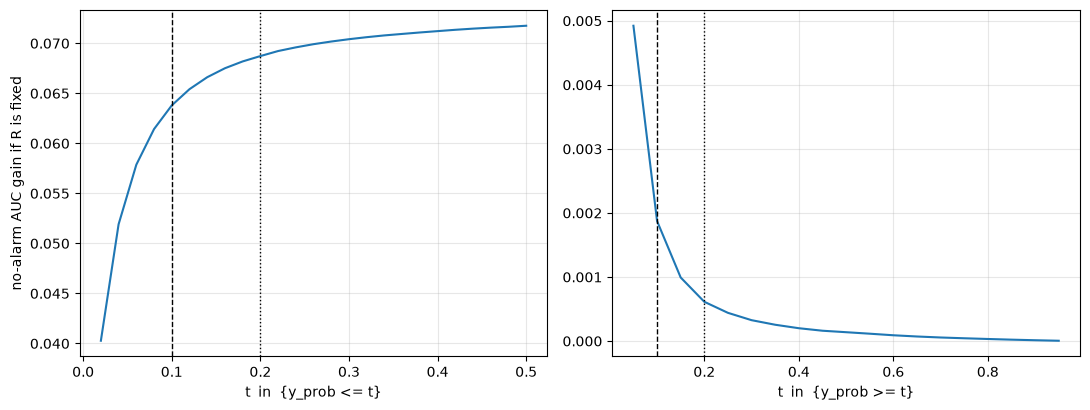

In [5]:
from tqdm.auto import tqdm

no_alarm = frame.loc[frame[ALARM_SPLIT_COL] == "no alarm"].copy()
y_na = no_alarm[TARGET_COLUMN].to_numpy()
if not np.all(y_na == y_na.astype(np.int64)):
    raise ValueError("is_fraud is not integer-valued")
y_na = y_na.astype(np.int64)
p_na = no_alarm[PROB_COL].to_numpy(dtype=np.float64)
fold_na = no_alarm[FOLD_COL].to_numpy()
n_na = len(no_alarm)
n_fraud_na = int(np.sum(y_na == 1))
base_na = float(roc_auc_score(y_na, p_na))
y_all = frame[TARGET_COLUMN].to_numpy().astype(np.int64)
p_all = frame[PROB_COL].to_numpy(dtype=np.float64)
no_alarm_pos = np.flatnonzero(frame[ALARM_SPLIT_COL].to_numpy() == "no alarm")
base_pooled = float(roc_auc_score(y_all, p_all))
print("no alarm n", n_na, "n_fraud", n_fraud_na, "auc", round(base_na, 6))
print("remaining no-alarm gap", round(1.0 - base_na, 6))
print("y_prob given not fraud")
print(
    no_alarm.loc[no_alarm[TARGET_COLUMN] == 0, PROB_COL]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(6)
)
print("y_prob given fraud")
print(
    no_alarm.loc[no_alarm[TARGET_COLUMN] == 1, PROB_COL]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(6)
)


def oracle_within(
    p: np.ndarray,
    *,
    y: np.ndarray,
    mask: np.ndarray,
) -> np.ndarray:
    p_fix = p.copy()
    if not np.any(mask):
        raise ValueError("region is empty")
    lo = float(np.min(p[mask]))
    hi = float(np.max(p[mask]))
    inside = mask
    p_fix[inside] = np.where(y[inside] == 1, hi, lo)
    return p_fix


def region_oracle_row(
    *,
    side: str,
    t1: float,
    t2: float,
    mask: np.ndarray,
) -> dict[str, object]:
    n = int(np.sum(mask))
    n_fraud = int(np.sum(mask & (y_na == 1)))
    if n == 0 or n_fraud == 0 or n_fraud == n:
        within = float("nan")
    else:
        within = float(roc_auc_score(y_na[mask], p_na[mask]))
    p_fix = oracle_within(p_na, y=y_na, mask=mask)
    auc_fix = float(roc_auc_score(y_na, p_fix))
    p_all_fix = p_all.copy()
    p_all_fix[no_alarm_pos] = p_fix
    pooled_fix = float(roc_auc_score(y_all, p_all_fix))
    return {
        "side": side,
        "t1": t1,
        "t2": t2,
        "n": n,
        "n_fraud": n_fraud,
        "share_of_rows": n / n_na,
        "share_of_fraud": n_fraud / n_fraud_na,
        "rate": n_fraud / n if n else float("nan"),
        "auc_within": within,
        "auc_no_alarm": auc_fix,
        "delta_no_alarm": auc_fix - base_na,
        "share_of_gap": (auc_fix - base_na) / (1.0 - base_na),
        "auc_pooled": pooled_fix,
        "delta_pooled": pooled_fix - base_pooled,
    }


left_ts = np.round(np.arange(0.02, 0.52, 0.02), 2)
n_left = len(left_ts)
left_rows: list[dict[str, object] | None] = [None] * n_left
for i in tqdm(range(n_left), desc="left tail"):
    t = float(left_ts[i])
    mask = p_na <= t
    left_rows[i] = region_oracle_row(side="left", t1=0.0, t2=t, mask=mask)
left_table = pd.DataFrame([row for row in left_rows if row is not None])

right_ts = np.round(np.arange(0.05, 1.0, 0.05), 2)
n_right = len(right_ts)
right_rows: list[dict[str, object] | None] = [None] * n_right
for i in tqdm(range(n_right), desc="right tail"):
    t = float(right_ts[i])
    mask = p_na >= t
    right_rows[i] = region_oracle_row(side="right", t1=t, t2=1.0, mask=mask)
right_table = pd.DataFrame([row for row in right_rows if row is not None])

print(DELIMITER_VALUE)
print("left tail {y_prob <= t}")
print(
    left_table.loc[
        left_table["t2"].isin([0.1, 0.2, 0.3, 0.5]),
        [
            "t2",
            "n",
            "n_fraud",
            "share_of_fraud",
            "auc_within",
            "delta_no_alarm",
            "share_of_gap",
            "delta_pooled",
        ],
    ].round(6)
)
print(DELIMITER_VALUE)
print("right tail {y_prob >= t}")
print(
    right_table.loc[
        right_table["t1"].isin([0.1, 0.2, 0.5, 0.8]),
        [
            "t1",
            "n",
            "n_fraud",
            "share_of_fraud",
            "auc_within",
            "delta_no_alarm",
            "share_of_gap",
            "delta_pooled",
        ],
    ].round(6)
)

best_left = left_table.loc[left_table["delta_no_alarm"].idxmax()]
best_right = right_table.loc[right_table["delta_no_alarm"].idxmax()]
print(DELIMITER_VALUE)
print(
    "best left t",
    float(best_left["t2"]),
    "delta",
    round(float(best_left["delta_no_alarm"]), 6),
    "share_of_gap",
    round(float(best_left["share_of_gap"]), 4),
)
print(
    "best right t",
    float(best_right["t1"]),
    "delta",
    round(float(best_right["delta_no_alarm"]), 6),
    "share_of_gap",
    round(float(best_right["share_of_gap"]), 4),
)

TAIL_SECTION = "no_alarm_tails"
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
axes[0].plot(left_table["t2"], left_table["delta_no_alarm"])
axes[0].axvline(0.1, color="black", linestyle="--", linewidth=1.0)
axes[0].axvline(0.2, color="black", linestyle=":", linewidth=1.0)
axes[0].set_xlabel("t  in  {y_prob <= t}")
axes[0].set_ylabel("no-alarm AUC gain if R is fixed")
axes[0].grid(True, alpha=0.3)
axes[1].plot(right_table["t1"], right_table["delta_no_alarm"])
axes[1].axvline(0.1, color="black", linestyle="--", linewidth=1.0)
axes[1].axvline(0.2, color="black", linestyle=":", linewidth=1.0)
axes[1].set_xlabel("t  in  {y_prob >= t}")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plot_path = (
    get_script_plot_dir(NOTEBOOK_STEM, section=TAIL_SECTION)
    / "no_alarm_tail_oracle_delta.png"
)
fig.savefig(plot_path, dpi=140)
print("saved", plot_path)
plt.show()

left_path = tables_dir / "no_alarm_left_tail_oracle.csv"
right_path = tables_dir / "no_alarm_right_tail_oracle.csv"
left_table.to_csv(left_path, index=False)
right_table.to_csv(right_path, index=False)
print("saved", left_path)
print("saved", right_path)


## No-alarm bands `(t1, t2]` and fold check

The same oracle on score bands. If the best band is a tail, a tree feature that fires at the extreme is the right shape. Then replay the winning left and right cuts inside each val fold.

In [ ]:
band_cuts = np.array([0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.8, 1.0])
n_cuts = len(band_cuts)
n_bands = n_cuts * (n_cuts - 1) // 2
band_rows: list[dict[str, object] | None] = [None] * n_bands
band_i = 0
for i in range(n_cuts - 1):
    for j in range(i + 1, n_cuts):
        t1 = float(band_cuts[i])
        t2 = float(band_cuts[j])
        if t1 == 0.0:
            mask = p_na <= t2
        else:
            mask = (p_na > t1) & (p_na <= t2)
        if not np.any(mask):
            continue
        band_rows[band_i] = region_oracle_row(
            side="band",
            t1=t1,
            t2=t2,
            mask=mask,
        )
        band_i += 1
band_table = pd.DataFrame([row for row in band_rows if row is not None])
band_table = band_table.sort_values("delta_no_alarm", ascending=False)
print(band_table.head(12).round(6))
best_band = band_table.iloc[0]
print(DELIMITER_VALUE)
print(
    "best band",
    float(best_band["t1"]),
    float(best_band["t2"]),
    "delta",
    round(float(best_band["delta_no_alarm"]), 6),
    "share_of_gap",
    round(float(best_band["share_of_gap"]), 4),
    "n_fraud",
    int(best_band["n_fraud"]),
)
band_path = tables_dir / "no_alarm_band_oracle.csv"
band_table.to_csv(band_path, index=False)
print("saved", band_path)

best_left_t = float(best_left["t2"])
best_right_t = float(best_right["t1"])
fold_ids_na = np.sort(np.unique(fold_na))
n_folds_na = len(fold_ids_na)
fold_tail_rows: list[dict[str, object] | None] = [None] * (n_folds_na * 2)
fold_row_i = 0
for fold_i in range(n_folds_na):
    fold_id = int(fold_ids_na[fold_i])
    in_fold = fold_na == fold_id
    y_f = y_na[in_fold]
    p_f = p_na[in_fold]
    base_f = float(roc_auc_score(y_f, p_f))
    left_mask = p_f <= best_left_t
    right_mask = p_f >= best_right_t
    p_left = oracle_within(p_f, y=y_f, mask=left_mask)
    p_right = oracle_within(p_f, y=y_f, mask=right_mask)
    fold_tail_rows[fold_row_i] = {
        FOLD_COL: fold_id,
        "side": "left",
        "t": best_left_t,
        "auc": base_f,
        "auc_fixed": float(roc_auc_score(y_f, p_left)),
        "delta": float(roc_auc_score(y_f, p_left)) - base_f,
        "n_region": int(np.sum(left_mask)),
        "n_fraud_region": int(np.sum(left_mask & (y_f == 1))),
    }
    fold_row_i += 1
    fold_tail_rows[fold_row_i] = {
        FOLD_COL: fold_id,
        "side": "right",
        "t": best_right_t,
        "auc": base_f,
        "auc_fixed": float(roc_auc_score(y_f, p_right)),
        "delta": float(roc_auc_score(y_f, p_right)) - base_f,
        "n_region": int(np.sum(right_mask)),
        "n_fraud_region": int(np.sum(right_mask & (y_f == 1))),
    }
    fold_row_i += 1
fold_tail = pd.DataFrame([row for row in fold_tail_rows if row is not None])
print(DELIMITER_VALUE)
print(fold_tail.round(6))
fold_tail_path = tables_dir / "no_alarm_tail_oracle_by_fold.csv"
fold_tail.to_csv(fold_tail_path, index=False)
print("saved", fold_tail_path)


## Takeaway: leftover no-alarm AUC is the low-score pile

Oracle: keep scores outside `R`; inside `R` send fraud to `max(p in R)` and non-fraud to `min(p in R)`. That is the best ranking a feature that only reorders inside `R` can get. Nested left tails are monotone in `t`, so `best t` is not a cut — read **share of the remaining gap** instead.

No-alarm base AUC **0.9267**, remaining gap **0.0733**.

| region | rows | fraud | share of gap | Δ no-alarm | Δ pooled |
|---|---:|---:|---:|---:|---:|
| `{p ≤ 0.02}` | 91.2% | 24.2% | **55.0%** | +0.0403 | +0.0272 |
| `{p ≤ 0.05}` | 96.2% | 40.4% | **75.4%** | +0.0553 | +0.0388 |
| `{p ≤ 0.10}` | 98.1% | 54.2% | **87.1%** | +0.0638 | +0.0460 |
| `{p ≤ 0.20}` | 99.1% | 67.6% | **93.8%** | +0.0687 | +0.0508 |
| `{p ≥ 0.10}` | 1.9% | 45.8% | 2.6% | +0.0019 | +0.0025 |
| `(0.02, 1]` | 8.8% | 75.8% | 18.5% | +0.0135 | +0.0134 |

`{p ≤ 0.1}` is not a small tail: 634,781 rows, fraud rate 0.59%. The **true** left pile is `{p ≤ 0.02}`: 1,674 buried frauds mixed with 588k non-frauds (rate 0.28%). The high-score tail is already ranked; fixing it barely moves AUC.

Every fold repeats the same shape (left `t=0.5` Δ ≈ 0.068–0.075; right `t=0.05` Δ ≈ 0.005).

A tree feature (including the fraud CDFs) helps only if it **splits that low-score pile**. A local rule on a tiny extreme — origin cube, hard-zero, high `y_prob` — cannot recover most of the 0.073.